In [1]:
import os
import pandas as pd

In [2]:
os.chdir("E:/Jupyter/K/Maize2")
#管理措施 = pd.read_excel("Wheat_原数据管理措施组合_V1.xls", engine='xlrd')
管理措施 = pd.read_csv("管理措施组合_Wheat.csv")
空间措施 = pd.read_csv("Wheat_空间数据_V1.csv")
os.chdir("E:/Jupyter/K/Wheat2/predict_test_ML")

In [7]:
new_tables = {}

# 循环遍历管理措施的每一行，生成新表格并提取对应的行内容作为表名
for i in range(len(管理措施)):
    # 生成表格名称
    table_name = "Table_" + "_".join(map(str, 管理措施.iloc[i].values))
    
    # 生成新表格，将空间措施的前11列作为初始数据，注意修改数字
    new_table = 空间措施.iloc[:, :11].copy()
    
    # 添加管理措施对应行的内容到新表格
    for j in range(len(管理措施.columns)):
        # 添加管理措施内容到新表格的第 j + 11 列
        new_table[管理措施.columns[j]] = 管理措施.iloc[i, j]
    
    # 将新表格添加到字典中
    new_tables[i] = new_table
    
    # 导出新生成的表格为CSV文件
    new_table.to_csv(f"{table_name}.csv", index=False)

In [10]:
input_path = "D:/For working/K/Wheat_V5/Wheat_原数据建模_V3.csv"
output_path = "D:/For working/K/Wheat_V5/Wheat_K_建模结果_V3.csv"

# 读取 CSV 文件
data = pd.read_csv(input_path)

# 查看数据前几行（相当于 R 的 View()）
print(data.head())

# 选择指定的列（注意 Python 索引从 0 开始，R 从 1 开始）
# 这里直接使用列位置索引（iloc），对应 R 代码的 c(3,4,5...,21)
# 注意 Python 的 iloc 是前闭后开区间，所以要比 R 的索引多 +1
subset_data = data.iloc[:, [2,3,4,5,6,7,8,9,10,11,12,14,15,16,17,18,19,20,21]]

# 导出为 CSV 文件
subset_data.to_csv(output_path, index=False) #注意核对生成的文件是否为想要的结果

   Precipitation  Temperature  Seasonal_Tem  Seasonal_Pre  Seasonal_ET0  Sand  \
0          297.0     5.935581      2.999366    140.094910    635.121094  40.0   
1          318.0     5.968170      3.673813    139.065231    647.817627  41.0   
2          292.0     6.198420      3.307598    146.452194    633.056763  40.0   
3          539.0    13.640802     12.546224    217.249695    806.178955  47.0   
4          290.0     6.293753      3.367132    150.817322    632.912048  40.0   

   Clay    BD   pH    OM  ...   Crop  Irrigation  Density Time Approach Type  \
0  20.0  1.49  8.3  2.56  ...  Wheat          I1       D1   T1       A1  Ty0   
1  26.0  1.40  8.5  1.18  ...  Wheat          I1       D1   T1       A1  Ty1   
2  20.0  1.49  8.6  2.35  ...  Wheat          I1       D1   T1       A1  Ty0   
3  19.0  1.38  8.2  0.83  ...  Wheat          I1       D0   T1       A1  Ty1   
4  20.0  1.49  8.5  2.62  ...  Wheat          I1       D0   T1       A1  Ty0   

  Straw_return         K2O   Yie

In [1]:
#准备10折验证和建模
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:

# 设置文件路径
file_path = "E:/Jupyter/K/Maize2/Maize_smalldata_建模结果.csv"

# 读取数据
optimal_Yield_train1 = pd.read_csv(file_path)

# 分类变量列名
categorical_cols = ['Irrigation', 'Density', 'Time', 'Approach', 'Type', 'Straw_return']

# 转换为category类型（类似R的factor）
for col in categorical_cols:
    optimal_Yield_train1[col] = optimal_Yield_train1[col].astype('category')

# 准备特征和目标变量
X = optimal_Yield_train1.drop(columns=['Yield'])
y = optimal_Yield_train1['Yield']

# 预处理：对分类变量进行one-hot编码
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
    ],
    remainder='passthrough'
)

X_processed = preprocessor.fit_transform(X)

# 10折交叉验证设置
kfold = KFold(n_splits=10, shuffle=True, random_state=123456)

# 参数网格（相当于tuneLength=10）
param_grid = {
    'max_features': np.arange(1, min(21, X_processed.shape[1]), 2)  # mtry候选值
}

# 创建随机森林模型
rf = RandomForestRegressor(n_estimators=500, random_state=123456, oob_score=True)

# 网格搜索（使用RMSE作为评估指标）
grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=kfold,
    scoring='neg_root_mean_squared_error',
    n_jobs=2,
    verbose=2
)

# 执行网格搜索
print("开始交叉验证调优...")
grid_search.fit(X_processed, y)

# 输出最佳参数
print("\n最佳参数:")
print(grid_search.best_params_)
best_mtry = grid_search.best_params_['max_features']
print(f"\n最佳mtry值: {best_mtry}")

开始交叉验证调优...
Fitting 10 folds for each of 10 candidates, totalling 100 fits

最佳参数:
{'max_features': 9}

最佳mtry值: 9


In [4]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
import matplotlib.pyplot as plt
import seaborn as sns
import os
from tqdm import tqdm
import joblib

In [5]:
np.random.seed(123456)

# 读取数据
file_path = "E:/Jupyter/K/Maize2/Maize_smalldata_建模结果.csv"

# 读取数据
data = pd.read_csv(file_path)

# 分类变量列名
categorical_cols = ['Irrigation', 'Density', 'Time', 'Approach', 'Type', 'Straw_return']

# 转换为category类型（类似R的factor）
for col in categorical_cols:
    data[col] = data[col].astype('category')

In [6]:
# 7:3分割训练集和测试集
train, test = train_test_split(data, test_size=0.3, random_state=123456)

# 预处理：对分类变量进行one-hot编码
X_train = pd.get_dummies(train.drop(columns=['Yield']), columns=categorical_cols)
y_train = train['Yield']
X_test = pd.get_dummies(test.drop(columns=['Yield']), columns=categorical_cols)
y_test = test['Yield']

# 确保测试集具有与训练集相同的列
missing_cols = set(X_train.columns) - set(X_test.columns)
for col in missing_cols:
    X_test[col] = 0
X_test = X_test[X_train.columns]

In [7]:
# 创建并训练随机森林模型（mtry=17）
rf_model = RandomForestRegressor(
    n_estimators=500,
    max_features=9,  # 相当于R中的mtry
    random_state=123456,
    oob_score=True,
    n_jobs=2
)
rf_model.fit(X_train, y_train)

# 模型评估
train_pred = rf_model.predict(X_train)
test_pred = rf_model.predict(X_test)

print("\n模型性能评估:")
print(f"训练集RMSE: {np.sqrt(mean_squared_error(y_train, train_pred)):.4f}")
print(f"训练集R²: {r2_score(y_train, train_pred):.4f}")
print(f"测试集RMSE: {np.sqrt(mean_squared_error(y_test, test_pred)):.4f}")
print(f"测试集R²: {r2_score(y_test, test_pred):.4f}")
print(f"OOB Score: {rf_model.oob_score_:.4f}")


模型性能评估:
训练集RMSE: 357.8977
训练集R²: 0.9712
测试集RMSE: 859.5641
测试集R²: 0.8482
OOB Score: 0.8347


正在预测 K2O = 0 的情况...
正在预测 K2O = 15 的情况...
正在预测 K2O = 30 的情况...
正在预测 K2O = 45 的情况...
正在预测 K2O = 60 的情况...
正在预测 K2O = 75 的情况...
正在预测 K2O = 90 的情况...
正在预测 K2O = 105 的情况...
正在预测 K2O = 120 的情况...

不同K2O梯度下的产量预测结果:
 K2O   Avg_Yield   Std_Yield   Min_Yield  Median_Yield    Max_Yield
   0 8496.938213 1639.105503 4535.851452   8217.544564 13093.258923
  15 8601.441204 1615.018657 4629.105489   8360.859055 13152.323693
  30 8798.061176 1694.162690 4840.853960   8636.654799 13793.710398
  45 8953.376950 1751.652459 5022.149634   8739.797260 14151.980864
  60 9102.953671 1810.168075 5089.073450   8848.835825 14284.412253
  75 9180.484651 1833.186597 5043.698560   8888.897343 14296.119273
  90 9253.816255 1869.601685 5021.243560   8936.147909 14378.324247
 105 9294.355092 1889.826143 5023.026960   8956.243624 14640.871507
 120 9381.300653 1894.978624 4952.833180   8974.333831 14672.939447

相对于K2O=0的产量变化百分比:
K2O=  0:   0.00%
K2O= 15:   1.23%
K2O= 30:   3.54%
K2O= 45:   5.37%
K2O= 60:   7.13%
K2O= 75:

C:\Users\weizb\AppData\Local\Temp\ipykernel_24244\3041333042.py:92: UserWarning: Glyph 39044 (\N{CJK UNIFIED IDEOGRAPH-9884}) missing from current font.
  plt.tight_layout()
C:\Users\weizb\AppData\Local\Temp\ipykernel_24244\3041333042.py:92: UserWarning: Glyph 27979 (\N{CJK UNIFIED IDEOGRAPH-6D4B}) missing from current font.
  plt.tight_layout()
C:\Users\weizb\AppData\Local\Temp\ipykernel_24244\3041333042.py:92: UserWarning: Glyph 20135 (\N{CJK UNIFIED IDEOGRAPH-4EA7}) missing from current font.
  plt.tight_layout()
C:\Users\weizb\AppData\Local\Temp\ipykernel_24244\3041333042.py:92: UserWarning: Glyph 37327 (\N{CJK UNIFIED IDEOGRAPH-91CF}) missing from current font.
  plt.tight_layout()
C:\Users\weizb\AppData\Local\Temp\ipykernel_24244\3041333042.py:92: UserWarning: Glyph 22522 (\N{CJK UNIFIED IDEOGRAPH-57FA}) missing from current font.
  plt.tight_layout()
C:\Users\weizb\AppData\Local\Temp\ipykernel_24244\3041333042.py:92: UserWarning: Glyph 20110 (\N{CJK UNIFIED IDEOGRAPH-4E8E}) miss

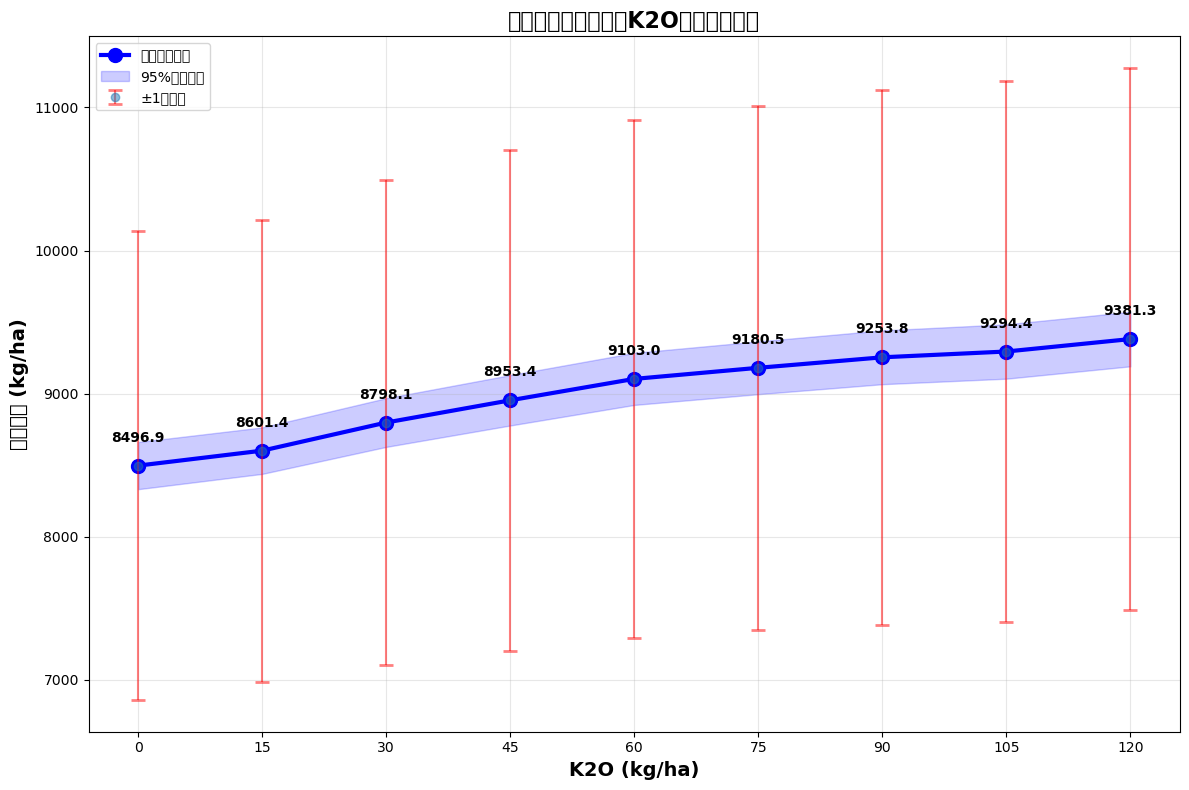

In [11]:
# 定义K2O梯度值
k2o_gradients = [0, 15, 30, 45, 60, 75, 90, 105, 120]

# 创建一个空列表来存储每个K2O梯度下的预测结果
all_predictions = []

# 对每个K2O梯度进行预测
for k2o_value in k2o_gradients:
    print(f"正在预测 K2O = {k2o_value} 的情况...")
    
    # 复制测试集
    X_test_modified = X_test.copy()
    
    # 将K2O列替换为当前梯度值
    X_test_modified['K2O'] = k2o_value
    
    # 确保列的顺序与训练时一致
    X_test_modified = X_test_modified[X_train.columns]
    
    # 进行预测
    y_pred = rf_model.predict(X_test_modified)
    
    # 计算平均预测值
    avg_pred = np.mean(y_pred)
    
    # 计算预测值的标准差
    std_pred = np.std(y_pred)
    
    # 计算预测值的95%置信区间
    conf_interval = 1.96 * std_pred / np.sqrt(len(y_pred))
    
    all_predictions.append({
        'K2O': k2o_value,
        'Avg_Yield': avg_pred,
        'Std_Yield': std_pred,
        'Conf_Interval': conf_interval,
        'Min_Yield': np.min(y_pred),
        'Max_Yield': np.max(y_pred),
        'Q25_Yield': np.percentile(y_pred, 25),
        'Median_Yield': np.median(y_pred),
        'Q75_Yield': np.percentile(y_pred, 75),
        'All_Predictions': y_pred  # 保存所有预测值供后续分析
    })

# 创建结果DataFrame
results_df = pd.DataFrame(all_predictions)

print("\n不同K2O梯度下的产量预测结果:")
print("=" * 80)
print(results_df[['K2O', 'Avg_Yield', 'Std_Yield', 'Min_Yield', 'Median_Yield', 'Max_Yield']].to_string(index=False))

# 计算相对于K2O=0的产量变化百分比
base_yield = results_df.loc[results_df['K2O'] == 0, 'Avg_Yield'].values[0]
results_df['Yield_Change_Pct'] = ((results_df['Avg_Yield'] - base_yield) / base_yield) * 100

print("\n相对于K2O=0的产量变化百分比:")
print("=" * 50)
for _, row in results_df.iterrows():
    print(f"K2O={row['K2O']:3d}: {row['Yield_Change_Pct']:6.2f}%")

# 可视化1: 平均产量随K2O变化
plt.figure(figsize=(12, 8))

# 绘制平均产量线
plt.plot(results_df['K2O'], results_df['Avg_Yield'], 'bo-', linewidth=3, markersize=10, label='平均预测产量')

# 添加误差线（标准差）
plt.errorbar(results_df['K2O'], results_df['Avg_Yield'], 
             yerr=results_df['Std_Yield'], fmt='o', 
             capsize=5, capthick=2, ecolor='red', alpha=0.5, label='±1标准差')

# 添加置信区间区域
plt.fill_between(results_df['K2O'], 
                 results_df['Avg_Yield'] - results_df['Conf_Interval'],
                 results_df['Avg_Yield'] + results_df['Conf_Interval'],
                 alpha=0.2, color='blue', label='95%置信区间')

plt.xlabel('K2O (kg/ha)', fontsize=14, fontweight='bold')
plt.ylabel('预测产量 (kg/ha)', fontsize=14, fontweight='bold')
plt.title('基于测试集的产量随K2O变化预测结果', fontsize=16, fontweight='bold')
plt.grid(True, alpha=0.3)
plt.legend(loc='best')
plt.xticks(k2o_gradients)

# 在图中标注数值
for i, row in results_df.iterrows():
    plt.annotate(f'{row["Avg_Yield"]:.1f}', 
                 (row['K2O'], row['Avg_Yield']),
                 xytext=(0, 15), textcoords='offset points',
                 ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

In [12]:
results_df.to_csv('Mean Value_K2O_gradient_predictions.csv', index=False)

# 用线性模型预测

In [13]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import warnings
warnings.filterwarnings('ignore')

# 设置随机种子
np.random.seed(123456)

# 读取数据
file_path = "E:/Jupyter/K/Maize2/Maize_smalldata_建模结果.csv"
data = pd.read_csv(file_path)

print(f"数据形状: {data.shape}")
print(f"数据列名: {list(data.columns)}")
print(f"K2O范围: {data['K2O'].min()} - {data['K2O'].max()}")

# 分类变量列名
categorical_cols = ['Irrigation', 'Density', 'Time', 'Approach', 'Type', 'Straw_return']

# 转换为category类型
for col in categorical_cols:
    data[col] = data[col].astype('category')

# 7:3分割训练集和测试集
train, test = train_test_split(data, test_size=0.3, random_state=123456)

print(f"训练集大小: {train.shape}")
print(f"测试集大小: {test.shape}")

# 预处理：对分类变量进行one-hot编码
X_train = pd.get_dummies(train.drop(columns=['Yield']), columns=categorical_cols)
y_train = train['Yield']
X_test = pd.get_dummies(test.drop(columns=['Yield']), columns=categorical_cols)
y_test = test['Yield']

print(f"One-hot编码后训练集特征数: {X_train.shape[1]}")

# 确保测试集具有与训练集相同的列
missing_cols = set(X_train.columns) - set(X_test.columns)
for col in missing_cols:
    X_test[col] = 0
X_test = X_test[X_train.columns]

print("=" * 80)
print("1. 线性回归模型建立与评估")
print("=" * 80)

# 创建并训练线性回归模型
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

# 获取模型系数
coefficients = pd.DataFrame({
    '特征': X_train.columns,
    '系数': linear_model.coef_
}).sort_values('系数', ascending=False)

print("\n线性回归模型系数 (绝对值最大的前20个):")
print(coefficients.head(20).to_string(index=False))

# 模型评估
train_pred = linear_model.predict(X_train)
test_pred = linear_model.predict(X_test)

print("\n" + "=" * 80)
print("模型性能评估")
print("=" * 80)
print(f"训练集RMSE: {np.sqrt(mean_squared_error(y_train, train_pred)):.4f}")
print(f"训练集MAE: {mean_absolute_error(y_train, train_pred):.4f}")
print(f"训练集R²: {r2_score(y_train, train_pred):.4f}")
print(f"测试集RMSE: {np.sqrt(mean_squared_error(y_test, test_pred)):.4f}")
print(f"测试集MAE: {mean_absolute_error(y_test, test_pred):.4f}")
print(f"测试集R²: {r2_score(y_test, test_pred):.4f}")

数据形状: (1266, 19)
数据列名: ['Seasonal_Tem', 'Seasonal_Pre', 'Seasonal_ET0', 'Sand', 'Clay', 'BD', 'pH', 'OM', 'TN', 'Olsen_P', 'Exc_K', 'Irrigation', 'Density', 'Time', 'Approach', 'Type', 'Straw_return', 'K2O', 'Yield']
K2O范围: 0.0 - 675.0
训练集大小: (886, 19)
测试集大小: (380, 19)
One-hot编码后训练集特征数: 26
1. 线性回归模型建立与评估

线性回归模型系数 (绝对值最大的前20个):
             特征          系数
             BD 4121.492210
       Type_Ty2 1350.807367
     Density_D2 1054.256327
Straw_return_S1  521.136217
    Approach_A1  344.749986
        Time_T2  326.986994
  Irrigation_I1  196.337858
             TN  133.290740
     Density_D1   66.571051
           Clay   29.612541
           Sand    5.454280
            K2O    4.242036
   Seasonal_Pre   -0.133088
   Seasonal_ET0   -1.147320
          Exc_K   -4.837500
        Olsen_P   -5.106426
             OM  -18.373898
             pH  -63.728940
  Irrigation_I0 -196.337858
   Seasonal_Tem -238.085072

模型性能评估
训练集RMSE: 1554.5448
训练集MAE: 1233.5135
训练集R²: 0.4567
测试集RMSE: 1665.4684
测试集M

In [14]:
# 定义K2O梯度值
k2o_gradients = [0, 15, 30, 45, 60, 75, 90, 105, 120]

# 创建一个空列表来存储每个K2O梯度下的预测结果
all_predictions = []

print("正在使用测试集预测不同K2O梯度下的产量...")
for k2o_value in tqdm(k2o_gradients):
    # 复制测试集
    X_test_modified = X_test.copy()
    
    # 将K2O列替换为当前梯度值
    X_test_modified['K2O'] = k2o_value
    
    # 确保列的顺序与训练时一致
    X_test_modified = X_test_modified[X_train.columns]
    
    # 进行预测
    y_pred = linear_model.predict(X_test_modified)
    
    # 计算统计量
    avg_pred = np.mean(y_pred)
    std_pred = np.std(y_pred)
    conf_interval = 1.96 * std_pred / np.sqrt(len(y_pred))
    
    all_predictions.append({
        'K2O': k2o_value,
        'Avg_Yield': avg_pred,
        'Std_Yield': std_pred,
        'Conf_Interval': conf_interval,
        'Min_Yield': np.min(y_pred),
        'Max_Yield': np.max(y_pred),
        'Q25_Yield': np.percentile(y_pred, 25),
        'Median_Yield': np.median(y_pred),
        'Q75_Yield': np.percentile(y_pred, 75),
        'All_Predictions': y_pred  # 保存所有预测值供后续分析
    })

# 创建结果DataFrame
results_df = pd.DataFrame(all_predictions)

print("\n不同K2O梯度下的产量预测结果 (基于线性回归模型):")
print("=" * 100)
print(results_df[['K2O', 'Avg_Yield', 'Std_Yield', 'Min_Yield', 'Median_Yield', 'Max_Yield']].to_string(index=False, float_format='%.2f'))

正在使用测试集预测不同K2O梯度下的产量...


100%|███████████████████████████████████████████████████████████████████████████████████| 9/9 [00:00<00:00, 433.70it/s]


不同K2O梯度下的产量预测结果 (基于线性回归模型):
 K2O  Avg_Yield  Std_Yield  Min_Yield  Median_Yield  Max_Yield
   0    8684.16    1413.43    5206.19       8683.91   12260.12
  15    8747.79    1413.43    5269.82       8747.54   12323.76
  30    8811.42    1413.43    5333.45       8811.17   12387.39
  45    8875.05    1413.43    5397.08       8874.80   12451.02
  60    8938.68    1413.43    5460.71       8938.43   12514.65
  75    9002.31    1413.43    5524.34       9002.06   12578.28
  90    9065.94    1413.43    5587.97       9065.69   12641.91
 105    9129.57    1413.43    5651.60       9129.32   12705.54
 120    9193.20    1413.43    5715.23       9192.95   12769.17


In [16]:
results_df.to_csv('Mean Value_K2O_gradient_predictions_LM.csv', index=False)

NameError: name 'k2o_coefficient' is not defined

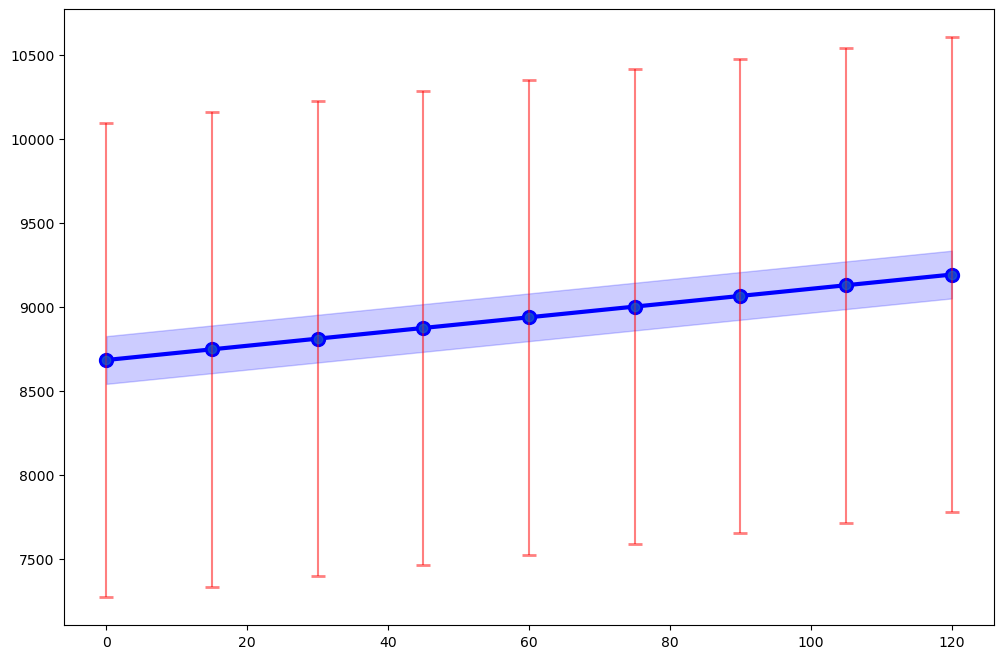

In [15]:
# 可视化1: 平均产量随K2O变化
plt.figure(figsize=(12, 8))

# 绘制平均产量线
plt.plot(results_df['K2O'], results_df['Avg_Yield'], 'bo-', linewidth=3, markersize=10, label='平均预测产量')

# 添加误差线（标准差）
plt.errorbar(results_df['K2O'], results_df['Avg_Yield'], 
             yerr=results_df['Std_Yield'], fmt='o', 
             capsize=5, capthick=2, ecolor='red', alpha=0.5, label='±1标准差')

# 添加置信区间区域
plt.fill_between(results_df['K2O'], 
                 results_df['Avg_Yield'] - results_df['Conf_Interval'],
                 results_df['Avg_Yield'] + results_df['Conf_Interval'],
                 alpha=0.2, color='blue', label='95%置信区间')

# 添加线性回归线
x_range = np.array(k2o_gradients)
# 计算线性趋势线：使用K2O系数和截距
intercept = linear_model.intercept_
# 计算其他特征的平均值对截距的贡献
other_features_mean = X_test.mean().values
other_coeffs = linear_model.coef_
# 去除K2O的贡献
k2o_idx = list(X_train.columns).index('K2O')
other_contribution = np.sum(other_coeffs * other_features_mean) - other_coeffs[k2o_idx] * other_features_mean[k2o_idx]
# 完整的线性预测线
linear_trend = intercept + other_contribution + k2o_coefficient * x_range
plt.plot(x_range, linear_trend, 'g--', linewidth=2, label='线性趋势线')

plt.xlabel('K2O (kg/ha)', fontsize=14, fontweight='bold')
plt.ylabel('预测产量 (kg/ha)', fontsize=14, fontweight='bold')
plt.title('线性回归模型: 基于测试集的产量随K2O变化预测结果', fontsize=16, fontweight='bold')
plt.grid(True, alpha=0.3)
plt.legend(loc='best')
plt.xticks(k2o_gradients)

# 在图中标注数值
for i, row in results_df.iterrows():
    plt.annotate(f'{row["Avg_Yield"]:.1f}', 
                 (row['K2O'], row['Avg_Yield']),
                 xytext=(0, 15), textcoords='offset points',
                 ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()


# 下面是承接随机森林模型的（被线性模型隔开了）

In [8]:
# 特征重要性分析
importance = rf_model.feature_importances_
feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': importance
}).sort_values('Importance', ascending=False)


In [9]:
def merge_categorical_importance(df):
    merged = {}
    for feature, imp in zip(df['Feature'], df['Importance']):
        if '_' in feature:  # one-hot编码的特征
            base_feature = feature.split('_')[0]
            merged[base_feature] = merged.get(base_feature, 0) + imp
        else:
            merged[feature] = merged.get(feature, 0) + imp
    return pd.DataFrame({
        'Feature': list(merged.keys()),
        'Importance': list(merged.values())
    }).sort_values('Importance', ascending=False)

merged_importance = merge_categorical_importance(feature_importance)


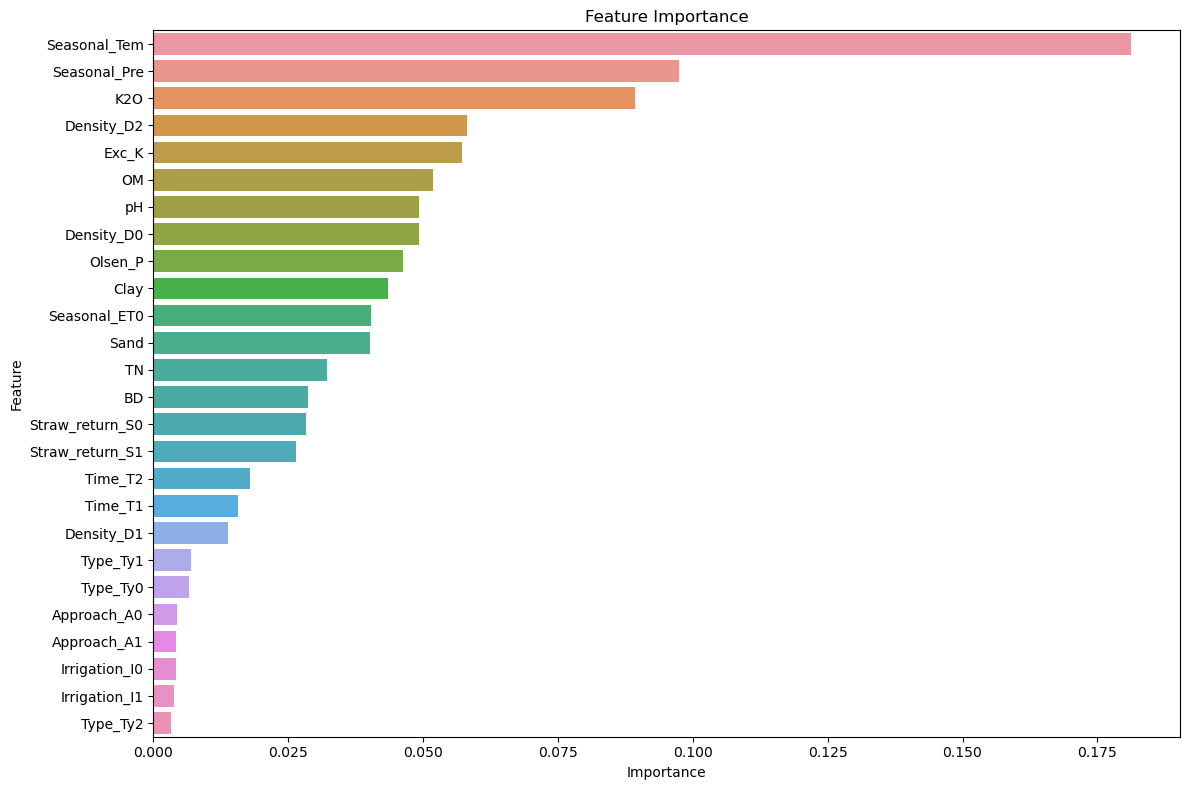

In [10]:
# 可视化特征重要性
plt.figure(figsize=(12, 8))
sns.barplot(x='Importance', y='Feature', data=feature_importance)
plt.title('Feature Importance')
plt.tight_layout()
plt.savefig('feature_importance_wheat.png')
plt.show()

In [13]:
import os
os.getcwd()

'E:\\Jupyter\\K\\Wheat2\\predict_test_ML'

In [14]:
os.chdir("E:/Jupyter/K/Wheat2/")

In [15]:
# 保存预测结果
train_pred_df = pd.DataFrame({'train_pred': train_pred})
test_pred_df = pd.DataFrame({'test_pred': test_pred})

train.to_csv('train_V1.csv', index=False)
train_pred_df.to_csv('train_pred_V1.csv', index=False)
test.to_csv('test_V1.csv', index=False)
test_pred_df.to_csv('test_pred_V1.csv', index=False)

In [16]:
# 计算评估指标
data_rf_R2 = r2_score(y_test, test_pred)
data_rf_MAE = mean_absolute_error(y_test, test_pred)
data_rf_RMSE = np.sqrt(mean_squared_error(y_test, test_pred))

# 计算除以100后的指标
data_rf_MAE_new = mean_absolute_error(y_test/100, test_pred/100)
data_rf_RMSE_new = np.sqrt(mean_squared_error(y_test/100, test_pred/100))

print("\n评估指标:")
print(f"R²: {data_rf_R2:.4f}")
print(f"MAE: {data_rf_MAE:.4f}")
print(f"RMSE: {data_rf_RMSE:.4f}")
print(f"MAE/100: {data_rf_MAE_new:.4f}")
print(f"RMSE/100: {data_rf_RMSE_new:.4f}")


评估指标:
R²: 0.8720
MAE: 395.0764
RMSE: 602.9096
MAE/100: 3.9508
RMSE/100: 6.0291


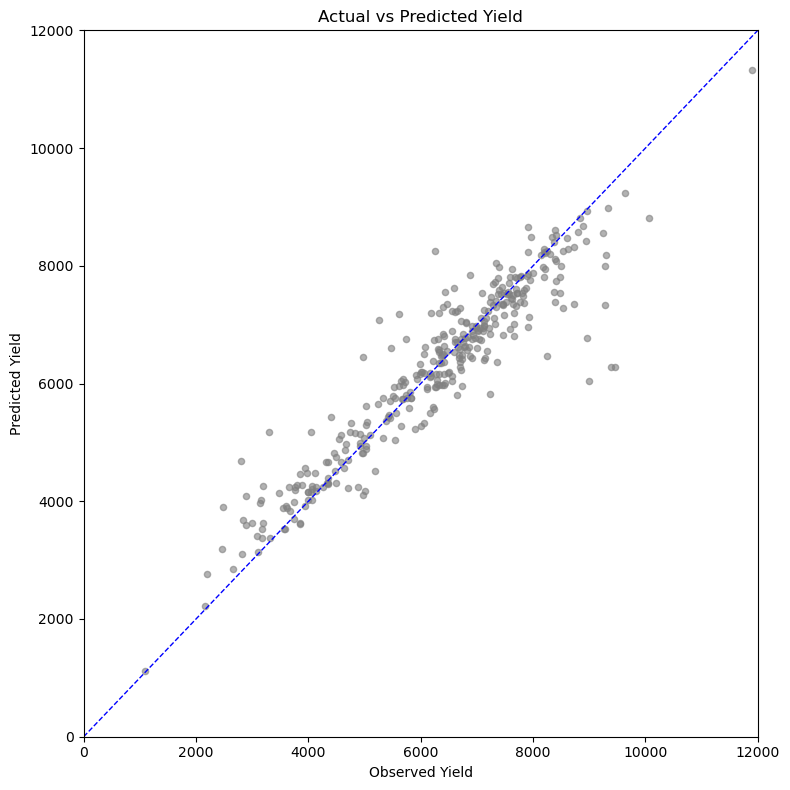

In [17]:
# 绘制实际值 vs 预测值散点图
plt.figure(figsize=(8, 8))
plt.scatter(y_test, test_pred, alpha=0.6, color='grey', s=20)
plt.plot([0, 12000], [0, 12000], 'b--', linewidth=1)  # 1:1线
plt.xlim(0, 12000)
plt.ylim(0, 12000)
plt.xlabel('Observed Yield')
plt.ylabel('Predicted Yield')
plt.title('Actual vs Predicted Yield')
plt.tight_layout()
plt.savefig('actual_vs_predicted.png')
plt.show()

In [19]:
# 准备训练数据
training = train.iloc[:, :19]  # 选择前19列
training.to_csv('training_V1.csv', index=False)

In [20]:
# 重新训练模型（使用相同的参数）
training_data = pd.read_csv('training_V1.csv')
for col in categorical_cols:
    training_data[col] = training_data[col].astype('category')

X_train_final = pd.get_dummies(training_data.drop(columns=['Yield']), columns=categorical_cols)
y_train_final = training_data['Yield']

final_model = RandomForestRegressor(
    n_estimators=500,
    max_features=19,
    random_state=123456,
    oob_score=True,
    n_jobs=2
)
final_model.fit(X_train_final, y_train_final)

RandomForestRegressor(max_features=19, n_estimators=500, n_jobs=2,
                      oob_score=True, random_state=123456)

In [21]:
# 批量预测函数
def batch_predict(input_folder, output_folder):
    os.makedirs(output_folder, exist_ok=True)
    file_list = [f for f in os.listdir(input_folder) if f.endswith('.csv')]
    
    for file in tqdm(file_list, desc="Processing files"):
        data = pd.read_csv(os.path.join(input_folder, file))
        
        # 处理分类变量
        for col in categorical_cols:
            data[col] = data[col].astype('category')
            data[col] = data[col].cat.set_categories(
                training_data[col].cat.categories
            )
        
        # 初始化结果DataFrame
        results = pd.DataFrame({'Code': range(1, len(data)+1)})
        
        # 对不同K2O值进行预测
        for k2o in range(0, 121, 15):
            data['K2O'] = k2o
            X_pred = pd.get_dummies(data, columns=categorical_cols)
            
            # 确保列一致
            missing_cols = set(X_train_final.columns) - set(X_pred.columns)
            for col in missing_cols:
                X_pred[col] = 0
            X_pred = X_pred[X_train_final.columns]
            
            predictions = final_model.predict(X_pred)
            results[str(k2o)] = predictions
        
        # 保存结果
        output_file = os.path.join(
            output_folder, 
            os.path.splitext(file)[0] + '_predictions.csv'
        )
        results.to_csv(output_file, index=False)

# 执行批量预测
input_folder = 'D:/For working/K/Wheat_V5/predict_test'
output_folder = 'D:/For working/K/Wheat_V5/results_test'
batch_predict(input_folder, output_folder)

Processing files: 100%|██████████████████████████████████████████████████████████████| 75/75 [1:13:04<00:00, 58.46s/it]


In [12]:
import os
import pandas as pd

# 设置工作目录
folder_path = "E:/Jupyter/K/Maize2/prediction-smalldata_NoA2"
output_dir = "E:/Jupyter/K/Maize2/Exported data"

# 获取文件夹中的所有CSV文件
file_names = [f for f in os.listdir(folder_path) if f.endswith('.csv')]
# 初始化字典存储各列数据（比列表更直观）
columns_data = {
    2: {},  # 对应第2列（Python索引从0开始，但CSV通常有标题列）
    3: {},
    4: {},
    5: {},
    6: {},
    7: {},
    8: {},
    9: {},
    10: {}
}

In [14]:
# 循环处理每个文件
for file in file_names:
    # 读取CSV文件
    file_path = os.path.join(folder_path, file)
    data = pd.read_csv(file_path)
    
    # 提取文件名（不含扩展名）
    file_name = os.path.splitext(file)[0]
    
    # 提取第2-10列并存入字典
    for col_idx in range(2, 11):  # 2-10列
        col_data = data.iloc[:, col_idx - 2]  # pandas列索引从0开始
        columns_data[col_idx][file_name] = col_data

# 将字典转换为DataFrame并保存
output_files = {
    2: "0.Second_columns_V1.csv",
    3: "15.Third_columns_V1.csv",
    4: "30.Forth_columns_V1.csv",
    5: "45.Fifth_columns_V1.csv",
    6: "60.Sixth_columns_V1.csv",
    7: "75.Seventh_columns_V1.csv",
    8: "90.Eighth_columns_V1.csv",
    9: "105.Ninth_columns_V1.csv",
    10: "120.Tenth_columns_V1.csv"
}

In [15]:
for col_idx, output_file in output_files.items():
    result_df = pd.DataFrame(columns_data[col_idx])
    output_path = os.path.join(output_dir, output_file)
    result_df.to_csv(output_path, index=False)
    print(f"Saved: {output_path} | Shape: {result_df.shape}")

Saved: E:/Jupyter/K/Maize2/Exported data\0.Second_columns_V1.csv | Shape: (639027, 96)
Saved: E:/Jupyter/K/Maize2/Exported data\15.Third_columns_V1.csv | Shape: (639027, 96)
Saved: E:/Jupyter/K/Maize2/Exported data\30.Forth_columns_V1.csv | Shape: (639027, 96)
Saved: E:/Jupyter/K/Maize2/Exported data\45.Fifth_columns_V1.csv | Shape: (639027, 96)
Saved: E:/Jupyter/K/Maize2/Exported data\60.Sixth_columns_V1.csv | Shape: (639027, 96)
Saved: E:/Jupyter/K/Maize2/Exported data\75.Seventh_columns_V1.csv | Shape: (639027, 96)
Saved: E:/Jupyter/K/Maize2/Exported data\90.Eighth_columns_V1.csv | Shape: (639027, 96)
Saved: E:/Jupyter/K/Maize2/Exported data\105.Ninth_columns_V1.csv | Shape: (639027, 96)
Saved: E:/Jupyter/K/Maize2/Exported data\120.Tenth_columns_V1.csv | Shape: (639027, 96)
